In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load Telecom Churn Dataset
df_churn = pd.read_csv('churn-bigml-80.csv')
print(f"Dataset Shape: {df_churn.shape}")
print(f"Missing Values: {df_churn.isnull().sum().sum()}")
print("\n--- Target Class Distribution (Churn) ---")
print(df_churn['Churn'].value_counts(normalize=True).round(4) * 100)

# 2. Preprocess Categorical & Redundant Features
# Convert binary Yes/No plans and boolean target to 0/1; drop high-cardinality State (51 categories)
df_proc = df_churn.drop(columns=['State']).copy()
df_proc['International plan'] = df_proc['International plan'].map({'No': 0, 'Yes': 1})
df_proc['Voice mail plan'] = df_proc['Voice mail plan'].map({'No': 0, 'Yes': 1})
df_proc['Churn'] = df_proc['Churn'].astype(int)

# Separate predictors and target
X = df_proc.drop(columns=['Churn'])
y = df_proc['Churn']

# 3. Stratified 80/20 Train/Test Split BEFORE scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 4. Fit StandardScaler strictly on X_train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTrain shape: {X_train_scaled.shape} | Test shape: {X_test_scaled.shape}")
print("Preprocessing and stratified split complete!")

Dataset Shape: (2666, 20)
Missing Values: 0

--- Target Class Distribution (Churn) ---
Churn
False    85.45
True     14.55
Name: proportion, dtype: float64

Train shape: (2132, 18) | Test shape: (534, 18)
Preprocessing and stratified split complete!


/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- Classification Model Comparison (Test Set, N=534) ---


,Model,Accuracy,Precision (Churn),Recall (Churn),F1-Score,ROC-AUC
0,Logistic Regression,0.8390,0.3889,0.1795,0.2456,0.7538
1,Support Vector Machine (RBF),0.9064,0.8333,0.4487,0.5833,0.8638
2,Random Forest Classifier,0.9551,0.9821,0.7051,0.8209,0.8678


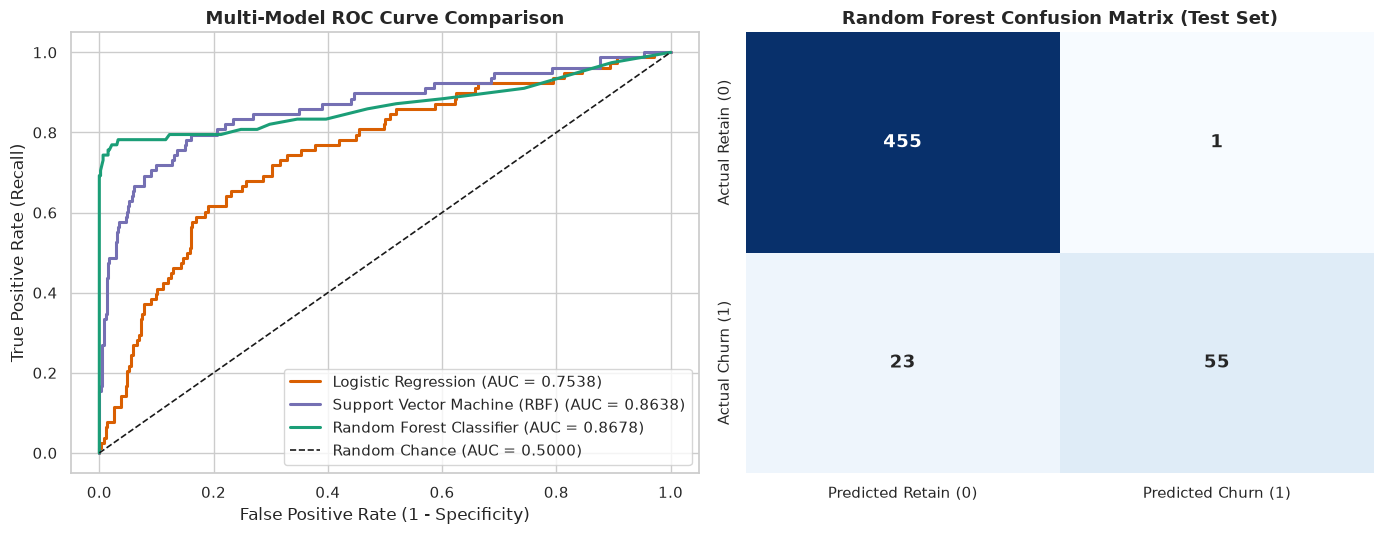

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

# 1. Initialize Classifiers
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Support Vector Machine (RBF)": SVC(kernel="rbf", probability=True, random_state=42),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=100, random_state=42)
}

# 2. Train, Evaluate & Collect Metrics
results = []
roc_data = {}

for name, clf in models.items():
    # Use scaled features for all models (essential for LR & SVM; invariant for RF)
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision (Churn)": round(prec, 4),
        "Recall (Churn)": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

df_clf_results = pd.DataFrame(results)
print("--- Classification Model Comparison (Test Set, N=534) ---")
display(df_clf_results)

# 3. Two-Panel Diagnostic Visualization (ROC Curves + Top Model Confusion Matrix)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Panel: Multi-Model ROC Curves
colors = ["#d95f02", "#7570b3", "#1b9e77"]
for (name, (fpr, tpr, auc)), col in zip(roc_data.items(), colors):
    axes[0].plot(fpr, tpr, lw=2.2, color=col, label=f"{name} (AUC = {auc:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1.2, label="Random Chance (AUC = 0.5000)")
axes[0].set_title("Multi-Model ROC Curve Comparison", fontsize=13, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

# Right Panel: Confusion Matrix for Random Forest
rf_preds = models["Random Forest Classifier"].predict(X_test_scaled)
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
    xticklabels=["Predicted Retain (0)", "Predicted Churn (1)"],
    yticklabels=["Actual Retain (0)", "Actual Churn (1)"],
    annot_kws={"size": 13, "weight": "bold"}
)
axes[1].set_title("Random Forest Confusion Matrix (Test Set)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()